# Clasificador de radiografías pediátricas con PyTorch (MedMNIST) — proyecto educativo

**Autor:** Abdieel Camargo ([@abdiellzz](https://github.com/abdiellzz)) · **Cuaderno:** `IAdoc.ipynb` · **Repositorio:** [abdiellzz/IAMED](https://github.com/abdiellzz/IAMED)
**Fecha de esta revisión de documentación:** 2026-11-09 · **Entorno de ejecución:** Google Colab, GPU Tesla T4 · **Semilla global:** 42

> ### ⚠️ Advertencia: este trabajo NO tiene validez clínica
> Es un **ejercicio educativo y retrospectivo**. Los modelos **no son dispositivos médicos**,
> no están validados externamente y **no deben usarse para diagnosticar, descartar ni
> priorizar** a ningún paciente. Las imágenes se reducen a **28 × 28 píxeles** y proceden de
> un único conjunto de datos público.

**Conjunto de datos:** PneumoniaMNIST (MedMNIST v2), compuesto por radiografías de tórax
pediátricas. Particiones oficiales: **train 4 708 · val 524 · test 624**; clases
`0 = normal`, `1 = pneumonia`.

**Cómo citar los datos:** Yang, J., Shi, R., Wei, D., Liu, Z., Zhao, L., Ke, B., Pfister, H.,
& Ni, B. (2023). *MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical
image classification.* Scientific Data, 10(1), 41. https://doi.org/10.1038/s41597-022-01721-8
— y el origen de las imágenes: Kermany, D. S., Goldbaum, M., Cai, W., et al. (2018).
*Identifying medical diagnoses and treatable diseases by image-based deep learning.*
Cell, 172(5), 1122–1131.e9. https://doi.org/10.1016/j.cell.2018.02.010

**Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todas*. El cuaderno instala sus
dependencias (`medmnist`, `optuna`) y descarga los datos automáticamente. En CPU funciona
igual, solo más lento.

---

# Clasificador de radiografías con MedMNIST y PyTorch (proyecto educativo)

este proyecto es solo educativo. El modelo **no sirve para diagnosticar** a ninguna persona.

---

## 1. Elegir el conjunto de datos

**MedMNIST** es una colección de conjuntos de imágenes médicas preparados en un tamaño pequeño y con formato estándar. Tiene 12 conjuntos 2D (radiografías, células de la sangre, piel, tejidos, etc.), lo que la hace ideal para aprender.

Elegimos **PneumoniaMNIST** por estas razones:

- **Imagen:** radiografía de tórax de un niño, en escala de grises y reducida a **28 × 28 píxeles**.
- **Etiqueta:** un solo número. `0` = **normal**, `1` = **neumonía**.
- **Origen:** radiografías pediátricas públicas (Kermany et al., 2018), preparadas por MedMNIST (Yang et al., 2023).

## 2. Instalar bibliotecas y descargar los datos

### Instalar MedMNIST

In [2]:
!pip install -q medmnist

### Importar bibliotecas, fijar la semilla y elegir GPU o CPU

In [3]:
import os
import random
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay,
)
import medmnist
from medmnist import INFO

# ---- Configuración del experimento ----
SEED = 42
DATASET = "pneumoniamnist"
EPOCHS = 15
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
DATA_DIR = "./datos_medmnist"
os.makedirs(DATA_DIR, exist_ok=True)

# ---- Reproducibilidad ----
def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semilla(SEED)

# ---- Configurar GPU/CPU ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cuda":
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

# ---- Cargar Metadatos ----
info = INFO[DATASET]
DataClass = getattr(medmnist, info["python_class"])
NOMBRES_CLASES = [info["label"][str(i)] for i in range(len(info["label"]))]
NUM_CLASES = len(NOMBRES_CLASES)
NUM_CANALES = info["n_channels"]

print("Tarea:", info["task"])
print("Clases:", NOMBRES_CLASES)
print("Canales de color:", NUM_CANALES)

Usando dispositivo: cuda
Nombre de la GPU: Tesla T4
Tarea: binary-class
Clases: ['normal', 'pneumonia']
Canales de color: 1


In [4]:
import torch

gpu_disponible = torch.cuda.is_available()
print("¿CUDA (GPU) está disponible?:", gpu_disponible)
if gpu_disponible:
    print("Dispositivo actual:", torch.cuda.current_device())
    print("Nombre de la GPU detectada:", torch.cuda.get_device_name(0))
else:
    print("No se ha detectado ninguna GPU activa. Si ya cambiaste el entorno a GPU, por favor ve al menú 'Entorno de ejecución' -> 'Reiniciar sesión' para aplicar los cambios.")

¿CUDA (GPU) está disponible?: True
Dispositivo actual: 0
Nombre de la GPU detectada: Tesla T4


### Descargar las tres divisiones oficiales (train, val, test)

In [5]:
datos_crudos = {}
for split in ["train", "val", "test"]:
    datos_crudos[split] = DataClass(split=split, download=True, root=DATA_DIR)
    print(f"{split:>5}: {len(datos_crudos[split]):>5} imágenes")

print()
for split, ds in datos_crudos.items():
    conteo = np.bincount(ds.labels.flatten(), minlength=NUM_CLASES)
    detalle = ", ".join(f"{NOMBRES_CLASES[i]}: {c}" for i, c in enumerate(conteo))
    print(f"{split:>5} -> {detalle}")

100%|██████████| 4.17M/4.17M [00:06<00:00, 657kB/s]


train:  4708 imágenes
  val:   524 imágenes
 test:   624 imágenes

train -> normal: 1214, pneumonia: 3494
  val -> normal: 135, pneumonia: 389
 test -> normal: 234, pneumonia: 390


## 3. Visualizar ejemplos con sus etiquetas

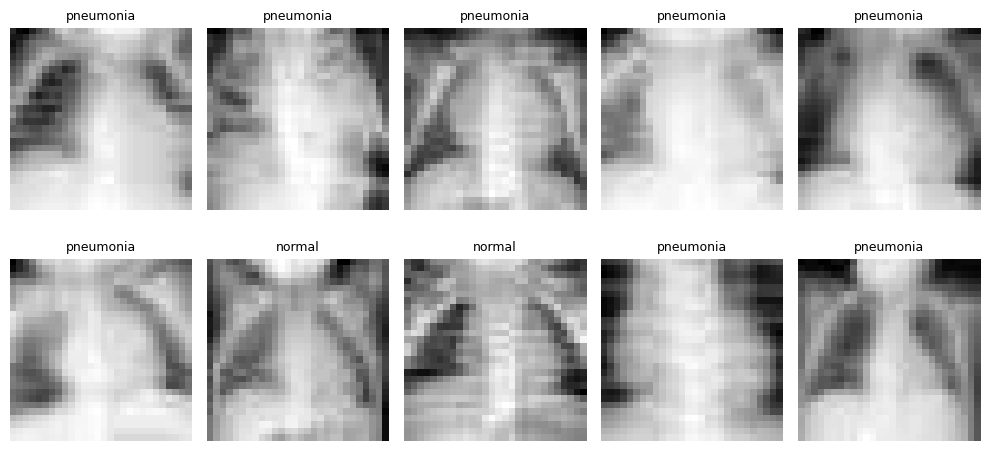

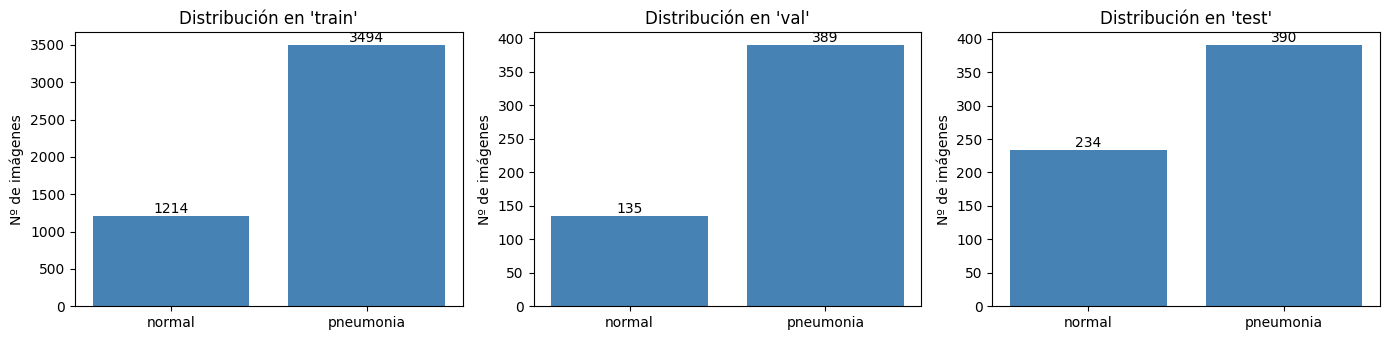

In [6]:
def mostrar_ejemplos(dataset, n=10):
    rng = np.random.default_rng(SEED)
    indices = rng.choice(len(dataset), size=n, replace=False)
    filas, columnas = 2, n // 2
    fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * 2, filas * 2.5))
    for ax, idx in zip(ejes.flat, indices):
        imagen, etiqueta = dataset[idx]
        ax.imshow(np.array(imagen), cmap="gray")
        ax.set_title(NOMBRES_CLASES[int(etiqueta[0])], fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

mostrar_ejemplos(datos_crudos["train"], n=10)

# Visualización de la distribución de clases
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (split, ds) in zip(ejes, datos_crudos.items()):
    conteo = np.bincount(ds.labels.flatten(), minlength=NUM_CLASES)
    ax.bar(NOMBRES_CLASES, conteo, color="steelblue")
    ax.set_title(f"Distribución en '{split}'")
    ax.set_ylabel("Nº de imágenes")
    for i, c in enumerate(conteo):
        ax.text(i, c, str(c), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 4. Preparar los datos sin fugas (DataLoaders)

In [7]:
media = [0.5] * NUM_CANALES
desv = [0.5] * NUM_CANALES

transform_train = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=media, std=desv),
])

transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=media, std=desv),
])

ds_train = DataClass(split="train", transform=transform_train, download=True, root=DATA_DIR)
ds_val   = DataClass(split="val",   transform=transform_eval,  download=True, root=DATA_DIR)
ds_test  = DataClass(split="test",  transform=transform_eval,  download=True, root=DATA_DIR)

generador = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=generador)
val_loader   = DataLoader(ds_val,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(ds_test,  batch_size=BATCH_SIZE, shuffle=False)

x_ejemplo, y_ejemplo = next(iter(train_loader))
print("Forma de un lote de imágenes:", tuple(x_ejemplo.shape))
print("Forma de las etiquetas:      ", tuple(y_ejemplo.shape))
print("Tamaños -> train:", len(ds_train), "| val:", len(ds_val), "| test:", len(ds_test))

Forma de un lote de imágenes: (64, 1, 28, 28)
Forma de las etiquetas:       (64, 1)
Tamaños -> train: 4708 | val: 524 | test: 624


## 5. Crear y entrenar una CNN con PyTorch

In [8]:
class CNNSencilla(nn.Module):
    def __init__(self, num_clases, num_canales=1):
        super().__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(num_canales, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_clases),
        )

    def forward(self, x):
        return self.clasificador(self.extractor(x))

modelo = CNNSencilla(NUM_CLASES, NUM_CANALES).to(device)
print(modelo)
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

prueba = torch.randn(2, NUM_CANALES, 28, 28).to(device)
print("Forma de la salida:", tuple(modelo(prueba).shape))

CNNSencilla(
  (extractor): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (clasificador): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(i

### Entrenar el modelo

In [9]:
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE)

def preparar_lote(imagenes, etiquetas):
    x = imagenes.to(device)
    y = etiquetas.view(-1).long().to(device)
    return x, y

def ejecutar_epoca(modelo, loader, criterio, optimizador=None):
    entrenando = optimizador is not None
    modelo.train(entrenando)
    perdida_total, aciertos, total = 0.0, 0, 0
    with torch.set_grad_enabled(entrenando):
        for imagenes, etiquetas in loader:
            x, y = preparar_lote(imagenes, etiquetas)
            salida = modelo(x)
            perdida = criterio(salida, y)
            if entrenando:
                optimizador.zero_grad()
                perdida.backward()
                optimizador.step()
            perdida_total += perdida.item() * x.size(0)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += x.size(0)
    return perdida_total / total, aciertos / total

historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado, mejor_epoca = None, 0

for epoca in range(1, EPOCHS + 1):
    t_loss, t_acc = ejecutar_epoca(modelo, train_loader, criterio, optimizador)
    v_loss, v_acc = ejecutar_epoca(modelo, val_loader, criterio)

    historial["train_loss"].append(t_loss)
    historial["train_acc"].append(t_acc)
    historial["val_loss"].append(v_loss)
    historial["val_acc"].append(v_acc)

    if v_loss < mejor_val_loss:
        mejor_val_loss = v_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        mejor_epoca = epoca

    print(f"Época {epoca:2d}/{EPOCHS} | "
          f"train: pérdida {t_loss:.4f}, acc {t_acc:.3f} | "
          f"val: pérdida {v_loss:.4f}, acc {v_acc:.3f}")

modelo.load_state_dict(mejor_estado)
print(f"\nMejor época seleccionada (mínima validación): {mejor_epoca}")

Época  1/15 | train: pérdida 0.2324, acc 0.904 | val: pérdida 0.2082, acc 0.929
Época  2/15 | train: pérdida 0.1277, acc 0.950 | val: pérdida 0.1062, acc 0.954
Época  3/15 | train: pérdida 0.1069, acc 0.959 | val: pérdida 0.1235, acc 0.954
Época  4/15 | train: pérdida 0.1057, acc 0.960 | val: pérdida 0.0915, acc 0.969
Época  5/15 | train: pérdida 0.1070, acc 0.958 | val: pérdida 0.0922, acc 0.964
Época  6/15 | train: pérdida 0.0957, acc 0.962 | val: pérdida 0.1570, acc 0.950
Época  7/15 | train: pérdida 0.0902, acc 0.967 | val: pérdida 0.0834, acc 0.971
Época  8/15 | train: pérdida 0.0725, acc 0.974 | val: pérdida 0.0653, acc 0.975
Época  9/15 | train: pérdida 0.0712, acc 0.975 | val: pérdida 0.0664, acc 0.973
Época 10/15 | train: pérdida 0.0761, acc 0.972 | val: pérdida 0.0941, acc 0.958
Época 11/15 | train: pérdida 0.0779, acc 0.971 | val: pérdida 0.0827, acc 0.971
Época 12/15 | train: pérdida 0.0665, acc 0.975 | val: pérdida 0.0942, acc 0.969
Época 13/15 | train: pérdida 0.0711, acc

## 6. Gráficas de pérdida y rendimiento

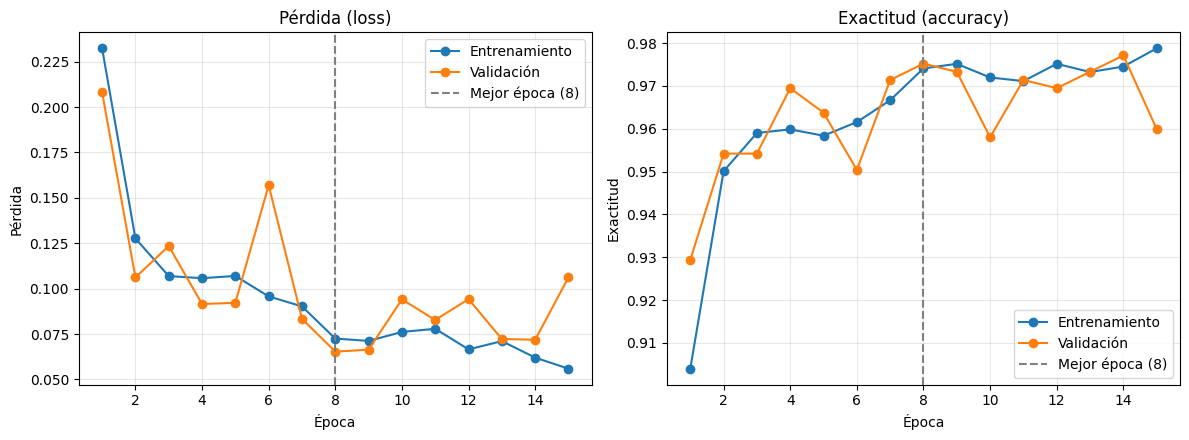

In [10]:
epocas = range(1, len(historial["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(epocas, historial["train_loss"], "o-", label="Entrenamiento")
ax1.plot(epocas, historial["val_loss"], "o-", label="Validación")
ax1.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época ({mejor_epoca})")
ax1.set_title("Pérdida (loss)")
ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epocas, historial["train_acc"], "o-", label="Entrenamiento")
ax2.plot(epocas, historial["val_acc"], "o-", label="Validación")
ax2.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época ({mejor_epoca})")
ax2.set_title("Exactitud (accuracy)")
ax2.set_xlabel("Época"); ax2.set_ylabel("Exactitud")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Evaluación con el conjunto de prueba

=== Métricas en el conjunto de PRUEBA ===
Exactitud (accuracy)    : 0.835
Precisión               : 0.792
Sensibilidad (recall)   : 0.997
F1                      : 0.883
Exactitud balanceada    : 0.781
Especificidad           : 0.564

Referencia: un modelo que siempre diga 'pneumonia' tendría una exactitud de 0.625

=== Informe por clase ===
              precision    recall  f1-score   support

      normal      0.992     0.564     0.719       234
   pneumonia      0.792     0.997     0.883       390

    accuracy                          0.835       624
   macro avg      0.892     0.781     0.801       624
weighted avg      0.867     0.835     0.822       624



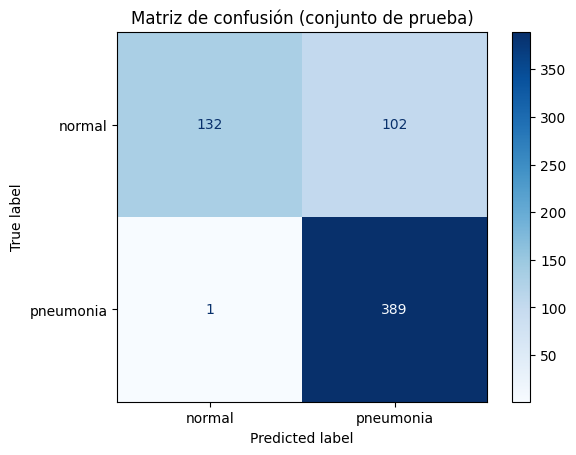

In [11]:
@torch.no_grad()
def predecir(modelo, loader):
    modelo.eval()
    y_true, y_pred, y_prob = [], [], []
    for imagenes, etiquetas in loader:
        x, y = preparar_lote(imagenes, etiquetas)
        probs = torch.softmax(modelo(x), dim=1)
        y_prob.append(probs.cpu().numpy())
        y_pred.append(probs.argmax(dim=1).cpu().numpy())
        y_true.append(y.cpu().numpy())
    return np.concatenate(y_true), np.concatenate(y_pred), np.concatenate(y_prob)

y_true, y_pred, y_prob = predecir(modelo, test_loader)
tipo_promedio = "binary" if NUM_CLASES == 2 else "macro"

metricas = {
    "Exactitud (accuracy)":   accuracy_score(y_true, y_pred),
    "Precisión":              precision_score(y_true, y_pred, average=tipo_promedio, zero_division=0),
    "Sensibilidad (recall)":  recall_score(y_true, y_pred, average=tipo_promedio, zero_division=0),
    "F1":                     f1_score(y_true, y_pred, average=tipo_promedio, zero_division=0),
    "Exactitud balanceada":   balanced_accuracy_score(y_true, y_pred),
}

cm = confusion_matrix(y_true, y_pred)
if NUM_CLASES == 2:
    tn, fp, fn, tp = cm.ravel()
    metricas["Especificidad"] = tn / (tn + fp)

print("=== Métricas en el conjunto de PRUEBA ===")
for nombre, valor in metricas.items():
    print(f"{nombre:<24}: {valor:.3f}")

clase_mayoritaria = np.bincount(y_true).argmax()
referencia = np.mean(y_true == clase_mayoritaria)
print(f"\nReferencia modelo trivial: {referencia:.3f}")

print("\n=== Informe detallado por clase ===")
print(classification_report(y_true, y_pred, target_names=NOMBRES_CLASES, digits=3, zero_division=0))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=NOMBRES_CLASES)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión (test)")
plt.show()

## 8. Predicciones correctas e incorrectas

Correctas: 521 | Incorrectas: 103


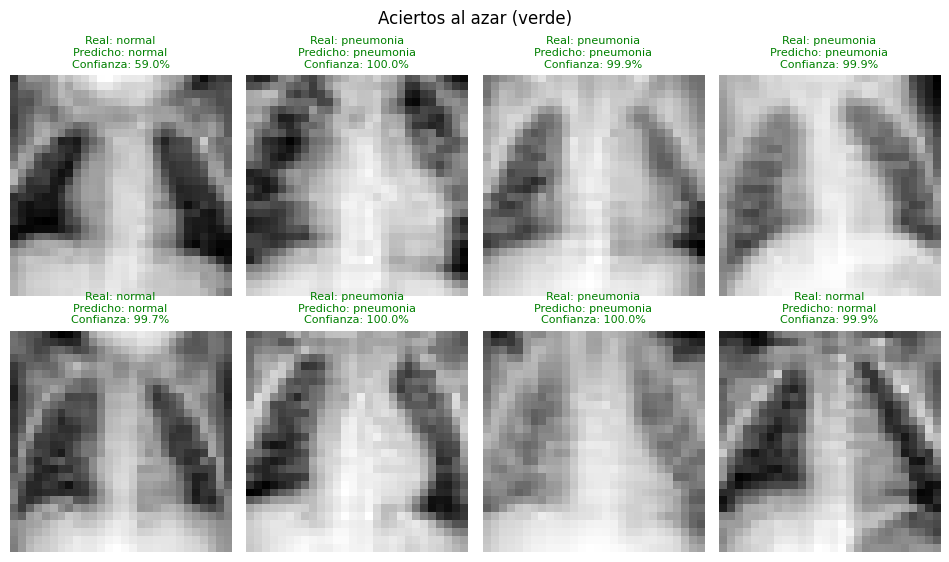

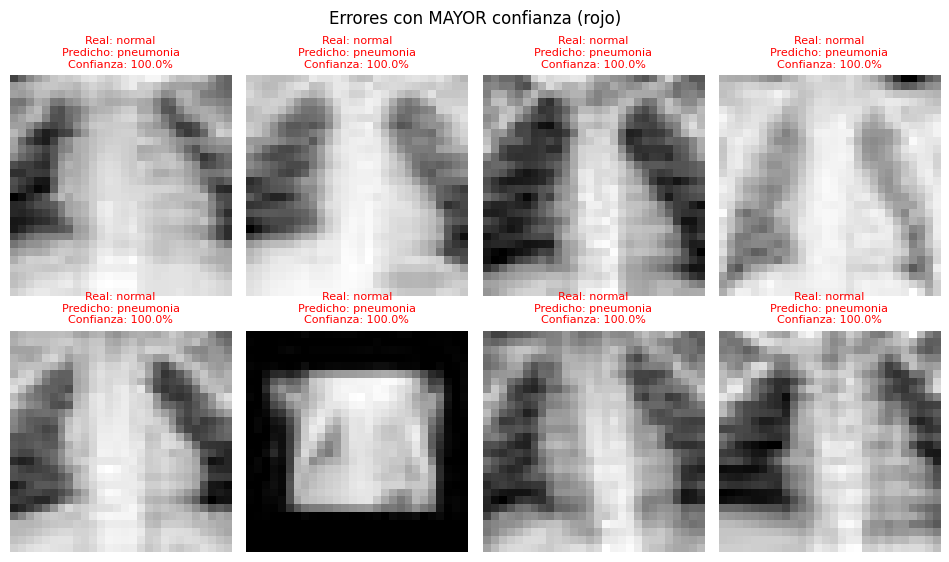

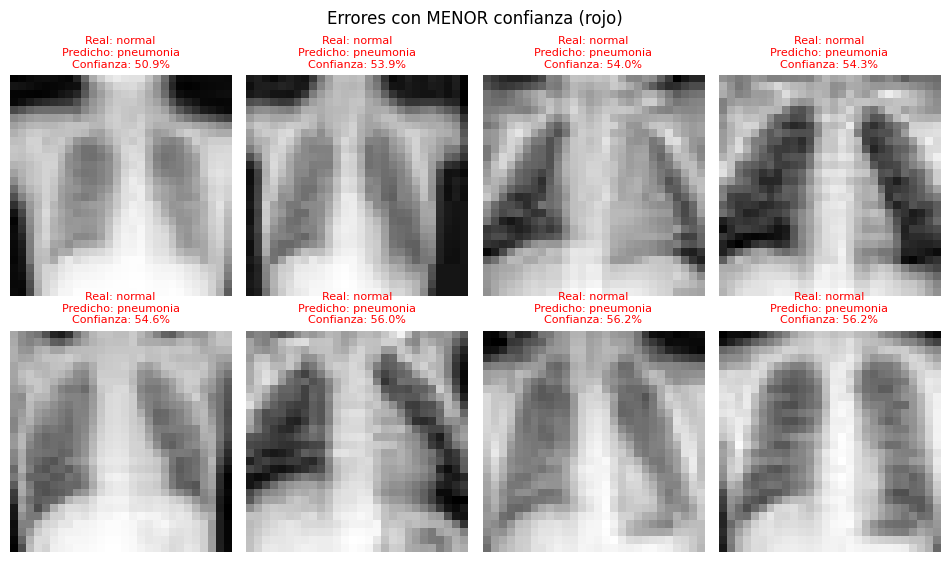

In [12]:
rng = np.random.default_rng(SEED)
correctas = np.where(y_true == y_pred)[0]
incorrectas = np.where(y_true != y_pred)[0]
print(f"Correctas: {len(correctas)} | Incorrectas: {len(incorrectas)}")

confianza_errores = y_prob[incorrectas].max(axis=1)
errores_seguros = incorrectas[np.argsort(-confianza_errores)][:8]
errores_dudosos = incorrectas[np.argsort(confianza_errores)][:8]
aciertos_al_azar = rng.choice(correctas, size=8, replace=False)

def mostrar_predicciones(indices, titulo):
    columnas = 4
    filas = int(np.ceil(len(indices) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * 2.4, filas * 2.9))
    for ax in np.array(ejes).flat:
        ax.axis("off")
    for ax, i in zip(np.array(ejes).flat, indices):
        imagen, _ = datos_crudos["test"][i]
        real = NOMBRES_CLASES[int(y_true[i])]
        pred = NOMBRES_CLASES[int(y_pred[i])]
        conf = 100 * y_prob[i, y_pred[i]]
        acierto = y_true[i] == y_pred[i]
        ax.imshow(np.array(imagen), cmap="gray")
        ax.set_title(f"Real: {real}\nPredicho: {pred}\nConfianza: {conf:.1f}%",
                     fontsize=8, color="green" if acierto else "red")
    fig.suptitle(titulo, fontsize=12)
    plt.tight_layout()
    plt.show()

mostrar_predicciones(aciertos_al_azar, "Aciertos al azar (verde)")
mostrar_predicciones(errores_seguros, "Errores con MAYOR confianza (rojo)")
mostrar_predicciones(errores_dudosos, "Errores con MENOR confianza (rojo)")

## 9. Guardar el modelo y volver a cargarlo

In [13]:
RUTA_MODELO = "modelo_cnn_pneumoniamnist.pt"

# 1) Guardar
torch.save({
    "estado_modelo": modelo.state_dict(),
    "num_clases": NUM_CLASES,
    "canales": NUM_CANALES,
    "nombres_clases": NOMBRES_CLASES,
    "dataset": DATASET,
}, RUTA_MODELO)
print("Modelo guardado en:", os.path.abspath(RUTA_MODELO))

# 2) Re-cargar
checkpoint = torch.load(RUTA_MODELO, map_location=device, weights_only=True)
modelo_cargado = CNNSencilla(checkpoint["num_clases"], checkpoint["canales"]).to(device)
modelo_cargado.load_state_dict(checkpoint["estado_modelo"])
modelo_cargado.eval()

# 3) Verificar consistencia
yt, yp, _ = predecir(modelo_cargado, test_loader)
print(f"Exactitud del modelo recargado: {accuracy_score(yt, yp):.3f}")

# 4) Inferencia individual
imagen_tensor, etiqueta_real = ds_test[0]
with torch.no_grad():
    probs = torch.softmax(modelo_cargado(imagen_tensor.unsqueeze(0).to(device)), dim=1)[0]
clase_predicha = int(probs.argmax())
print(f"\nImagen 0 -> Real: {NOMBRES_CLASES[int(etiqueta_real[0])]} | "
      f"Predicho: {NOMBRES_CLASES[clase_predicha]} ({probs[clase_predicha]*100:.1f}%)")

Modelo guardado en: /content/modelo_cnn_pneumoniamnist.pt
Exactitud del modelo recargado en prueba: 0.835

Imagen 0 -> real: pneumonia | predicho: pneumonia (100.0%)


AUC validación: 0.996
AUC prueba:     0.959

Umbral elegido con validación: 0.89 (exact. balanceada val: 0.973)

=== Conjunto de PRUEBA ===
Umbral 0.50    | exact 0.835 | sens 0.997 | espec 0.564 | exact.bal 0.781 | FN=1 FP=102
Umbral 0.89    | exact 0.896 | sens 0.977 | espec 0.761 | exact.bal 0.869 | FN=9 FP=56


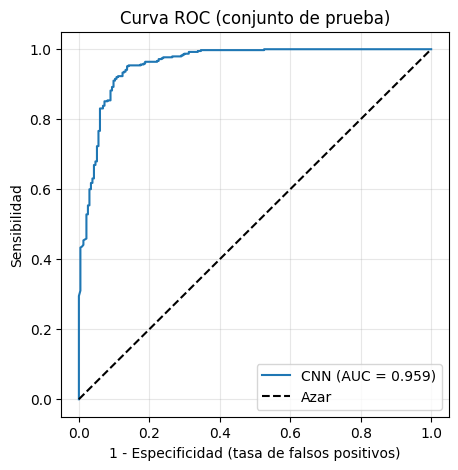

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score

# 1) Predicciones probabilísticas
yv_true, _, yv_prob = predecir(modelo, val_loader)
pv = yv_prob[:, 1]
pt = y_prob[:, 1]

# 2) Medir AUC global
print(f"AUC validación: {roc_auc_score(yv_true, pv):.3f}")
print(f"AUC prueba:     {roc_auc_score(y_true, pt):.3f}")

# 3) Optimizar umbral Bayesiano con el conjunto de Validación
umbrales = np.linspace(0.05, 0.95, 91)
mejor_umbral, mejor_bal = 0.5, 0
for u in umbrales:
    pred_u = (pv >= u).astype(int)
    bal = balanced_accuracy_score(yv_true, pred_u)
    if bal > mejor_bal:
        mejor_bal, mejor_umbral = bal, u
print(f"\nUmbral óptimo de decisión: {mejor_umbral:.2f} (Exactitud Balanceada Val: {mejor_bal:.3f})")

# 4) Validación cruzada en Prueba
def resumen(y, pred, nombre):
    cm = confusion_matrix(y, pred); tn, fp, fn, tp = cm.ravel()
    print(f"{nombre:<14} | exact {accuracy_score(y, pred):.3f} | "
          f"sens {tp/(tp+fn):.3f} | espec {tn/(tn+fp):.3f} | "
          f"exact.bal {balanced_accuracy_score(y, pred):.3f} | FN={fn} FP={fp}")

print("\n=== Resultados Comparativos (Prueba) ===")
resumen(y_true, (pt >= 0.5).astype(int), "Umbral 0.50")
resumen(y_true, (pt >= mejor_umbral).astype(int), f"Umbral {mejor_umbral:.2f}")

# 5) Graficar curva ROC
fpr, tpr, _ = roc_curve(y_true, pt)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"CNN (AUC = {roc_auc_score(y_true, pt):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("1 - Especificidad (Falsos Positivos)")
plt.ylabel("Sensibilidad (Verdaderos Positivos)")
plt.title("Curva ROC (Prueba)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [15]:
# 1) Calcular penalizaciones usando frecuencias de clase en entrenamiento
conteo_train = np.bincount(ds_train.labels.flatten(), minlength=NUM_CLASES)
pesos = 1.0 / conteo_train
pesos = pesos / pesos.sum() * NUM_CLASES
print("Conteo en train:", conteo_train)
print("Pesos asignados:", np.round(pesos, 3))

# 2) Instanciar red convolucional bajo semilla fija
fijar_semilla(SEED)
modelo_peso = CNNSencilla(NUM_CLASES, NUM_CANALES).to(device)

criterio_peso = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32).to(device))
optimizador_peso = torch.optim.Adam(modelo_peso.parameters(), lr=LEARNING_RATE)

# 3) Bucle de Entrenamiento Ponderado
historial_peso = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado_peso, mejor_epoca_peso = None, 0

for epoca in range(1, EPOCHS + 1):
    t_loss, t_acc = ejecutar_epoca(modelo_peso, train_loader, criterio_peso, optimizador_peso)
    v_loss, v_acc = ejecutar_epoca(modelo_peso, val_loader, criterio_peso)
    historial_peso["train_loss"].append(t_loss)
    historial_peso["train_acc"].append(t_acc)
    historial_peso["val_loss"].append(v_loss)
    historial_peso["val_acc"].append(v_acc)
    if v_loss < mejor_val_loss:
        mejor_val_loss = v_loss
        mejor_estado_peso = copy.deepcopy(modelo_peso.state_dict())
        mejor_epoca_peso = epoca
    print(f"Época {epoca:2d} | train loss: {t_loss:.4f} - acc: {t_acc:.3f} | val loss: {v_loss:.4f} - acc: {v_acc:.3f}")

modelo_peso.load_state_dict(mejor_estado_peso)
print(f"\nMejor época con pérdida balanceada: {mejor_epoca_peso}")

# 4) Evaluar impacto en el conjunto de Prueba
yt2, yp2, yp_prob2 = predecir(modelo_peso, test_loader)
pt2 = yp_prob2[:, 1]

print("\n=== COMPARATIVA CON ENFOQUE ADVERSARIO (u = 0.50) ===")
print(f"{'Modelo':<22}{'AUC':>7}{'Exact':>8}{'Sens':>8}{'Espec':>8}{'Bal':>8}")

pt_orig = y_prob[:, 1]
cm_orig = confusion_matrix(y_true, (pt_orig >= 0.5).astype(int))
tn_o, fp_o, fn_o, tp_o = cm_orig.ravel()

cm_peso = confusion_matrix(yt2, (pt2 >= 0.5).astype(int))
tn_p, fp_p, fn_p, tp_p = cm_peso.ravel()

print(f"{'Sin pesos (Línea de Base)':<22}{roc_auc_score(y_true, pt_orig):>7.3f}"
      f"{accuracy_score(y_true, (pt_orig>=0.5).astype(int)):>8.3f}"
      f"{tp_o/(tp_o+fn_o):>8.3f}"
      f"{tn_o/(tn_o+fp_o):>8.3f}"
      f"{balanced_accuracy_score(y_true, (pt_orig>=0.5).astype(int)):>8.3f}")

print(f"{'Con pesos (Balanceado)':<22}{roc_auc_score(yt2, pt2):>7.3f}"
      f"{accuracy_score(yt2, (pt2>=0.5).astype(int)):>8.3f}"
      f"{tp_p/(tp_p+fn_p):>8.3f}"
      f"{tn_p/(tn_p+fp_p):>8.3f}"
      f"{balanced_accuracy_score(yt2, (pt2>=0.5).astype(int)):>8.3f}")

# 5) Umbral Ponderado óptimo
yv_t2, _, yv_p2 = predecir(modelo_peso, val_loader)
pv2 = yv_p2[:, 1]
mejor_u2, mejor_bal2 = 0.5, 0
for u in np.linspace(0.05, 0.95, 91):
    bal = balanced_accuracy_score(yv_t2, (pv2 >= u).astype(int))
    if bal > mejor_bal2:
        mejor_bal2, mejor_u2 = bal, u
print(f"\nUmbral óptimo con pesos (validación): {mejor_u2:.2f}")
print(f"Exactitud balanceada en prueba final: "
      f"{balanced_accuracy_score(yt2, (pt2>=mejor_u2).astype(int)):.3f}")

Conteo en train: [1214 3494]
Pesos en la pérdida: [1.484 0.516]
Época  1 | train: 0.2369 / 0.895 | val: 0.1284 / 0.948
Época  2 | train: 0.1440 / 0.940 | val: 0.1018 / 0.958
Época  3 | train: 0.1334 / 0.945 | val: 0.1223 / 0.935
Época  4 | train: 0.1154 / 0.954 | val: 0.0895 / 0.969
Época  5 | train: 0.1048 / 0.960 | val: 0.0879 / 0.968
Época  6 | train: 0.1023 / 0.961 | val: 0.1963 / 0.884
Época  7 | train: 0.0990 / 0.956 | val: 0.0737 / 0.971
Época  8 | train: 0.0923 / 0.963 | val: 0.1127 / 0.931
Época  9 | train: 0.0925 / 0.964 | val: 0.0649 / 0.975
Época 10 | train: 0.0715 / 0.973 | val: 0.0756 / 0.975
Época 11 | train: 0.0750 / 0.967 | val: 0.0873 / 0.969
Época 12 | train: 0.0708 / 0.972 | val: 0.1664 / 0.968
Época 13 | train: 0.0737 / 0.972 | val: 0.0769 / 0.960
Época 14 | train: 0.0648 / 0.974 | val: 0.0593 / 0.971
Época 15 | train: 0.0637 / 0.976 | val: 0.0638 / 0.977

Mejor época: 14

=== COMPARACIÓN EN PRUEBA (umbral 0.5) ===
Modelo                    AUC   Exact    Sens   Es

=== Brier Score en PRUEBA (menor es mejor) ===
Modelo sin pesos: 0.1326
Modelo con pesos: 0.0964


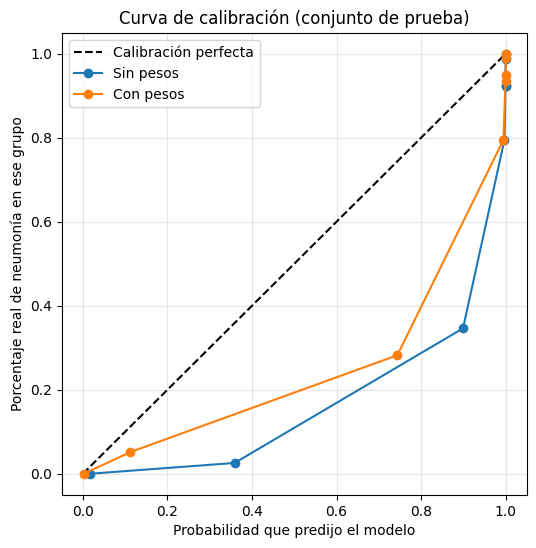

In [16]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

p_sin_pesos = y_prob[:, 1]
p_con_pesos = pt2

print("=== Brier Score (Menor puntuación indica mejor calibración) ===")
print(f"Modelo base (Sin pesos): {brier_score_loss(y_true, p_sin_pesos):.4f}")
print(f"Modelo balanceado (Con pesos): {brier_score_loss(y_true, p_con_pesos):.4f}")

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="Calibración ideal")

for nombre, probs in [("Sin pesos", p_sin_pesos), ("Con pesos", p_con_pesos)]:
    frac_real, media_pred = calibration_curve(y_true, probs, n_bins=8, strategy="quantile")
    plt.plot(media_pred, frac_real, "o-", label=nombre)

plt.xlabel("Confianza promedio prevista por el modelo")
plt.ylabel("Porcentaje empírico de casos de neumonía")
plt.title("Curva de Calibración")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [17]:
semillas = [42, 7, 123]

conteo_tr = np.bincount(ds_train.labels.flatten(), minlength=NUM_CLASES)
pesos_tr = 1.0 / conteo_tr
pesos_tr = pesos_tr / pesos_tr.sum() * NUM_CLASES

def entrenar_y_evaluar(seed, usar_pesos=False):
    fijar_semilla(seed)
    g = torch.Generator().manual_seed(seed)
    loader_tr = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g)

    m = CNNSencilla(NUM_CLASES, NUM_CANALES).to(device)
    if usar_pesos:
        crit = nn.CrossEntropyLoss(weight=torch.tensor(pesos_tr, dtype=torch.float32).to(device))
    else:
        crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE)

    mejor_loss, mejor_st = float("inf"), None
    for _ in range(EPOCHS):
        ejecutar_epoca(m, loader_tr, crit, opt)
        vl, _ = ejecutar_epoca(m, val_loader, crit)
        if vl < mejor_loss:
            mejor_loss = vl
            mejor_st = copy.deepcopy(m.state_dict())
    m.load_state_dict(mejor_st)

    yv_t, _, yv_p = predecir(m, val_loader)
    pv_s = yv_p[:, 1]
    mejor_u, mejor_bal = 0.5, 0
    for u in np.linspace(0.05, 0.95, 91):
        b = balanced_accuracy_score(yv_t, (pv_s >= u).astype(int))
        if b > mejor_bal:
            mejor_bal, mejor_u = b, u

    yt_s, _, pt_s = predecir(m, test_loader)
    p1 = pt_s[:, 1]
    return (
        roc_auc_score(yt_s, p1),
        balanced_accuracy_score(yt_s, (p1 >= 0.5).astype(int)),
        balanced_accuracy_score(yt_s, (p1 >= mejor_u).astype(int)),
        mejor_u,
    )

for nombre, usar_pesos in [("Sin pesos", False), ("Con pesos", True)]:
    resultados = np.array([entrenar_y_evaluar(s, usar_pesos) for s in semillas])
    medias = resultados.mean(axis=0)
    desvs = resultados.std(axis=0)
    print(f"\n=== {nombre} (Estadísticas sobre 3 semillas ejecutadas) ===")
    print(f"AUC:                   {medias[0]:.3f} ± {desvs[0]:.3f}")
    print(f"Exact. bal. (u=0.50):  {medias[1]:.3f} ± {desvs[1]:.3f}")
    print(f"Exact. bal. (u ópt.):  {medias[2]:.3f} ± {desvs[2]:.3f}")
    print(f"Umbral de decisión:   {medias[3]:.2f} ± {desvs[3]:.2f}")


=== Sin pesos (3 semillas) ===
AUC:                   0.966 ± 0.005
Exact. bal. (u=0.50):  0.781 ± 0.016
Exact. bal. (u ópt.):  0.846 ± 0.016
Umbral elegido:        0.80 ± 0.05

=== Con pesos (3 semillas) ===
AUC:                   0.967 ± 0.005
Exact. bal. (u=0.50):  0.829 ± 0.018
Exact. bal. (u ópt.):  0.853 ± 0.021
Umbral elegido:        0.69 ± 0.15


### 10. Automatización del Pipeline y AutoML con Optuna

In [18]:
def pipeline_completo(seed=SEED, usar_pesos=False, epochs=EPOCHS, verbose=True):
    fijar_semilla(seed)
    g = torch.Generator().manual_seed(seed)
    loader_tr = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g)

    if usar_pesos:
        conteo = np.bincount(ds_train.labels.flatten(), minlength=NUM_CLASES)
        w = 1.0 / conteo
        w = w / w.sum() * NUM_CLASES
        crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))
    else:
        crit = nn.CrossEntropyLoss()

    m = CNNSencilla(NUM_CLASES, NUM_CANALES).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE)

    mejor_loss, mejor_st = float("inf"), None
    for ep in range(epochs):
        ejecutar_epoca(m, loader_tr, crit, opt)
        vl, _ = ejecutar_epoca(m, val_loader, crit)
        if vl < mejor_loss:
            mejor_loss, mejor_st = vl, copy.deepcopy(m.state_dict())
        if verbose:
            print(f"  época {ep+1:2d}/{epochs} | val_loss {vl:.4f}")
    m.load_state_dict(mejor_st)

    yv_t, _, yv_p = predecir(m, val_loader)
    pv = yv_p[:, 1]
    mejor_u = max(np.linspace(0.05, 0.95, 91),
                  key=lambda u: balanced_accuracy_score(yv_t, (pv >= u).astype(int)))

    yt_s, _, pt_s = predecir(m, test_loader)
    p1 = pt_s[:, 1]
    return {"modelo": m, "auc": roc_auc_score(yt_s, p1),
            "bal_050": balanced_accuracy_score(yt_s, (p1 >= 0.5).astype(int)),
            "bal_opt": balanced_accuracy_score(yt_s, (p1 >= mejor_u).astype(int)),
            "umbral": mejor_u}

plan = [
    {"seed": 42,  "usar_pesos": False},
    {"seed": 42,  "usar_pesos": True},
    {"seed": 7,   "usar_pesos": True},
    {"seed": 123, "usar_pesos": True},
]
for cfg in plan:
    print(f"\n=== Configuración ejecutada: {cfg} ===")
    r = pipeline_completo(**cfg, verbose=False)
    print(f"  AUC {r['auc']:.3f} | bal(0.50) {r['bal_050']:.3f} | "
          f"bal(ópt) {r['bal_opt']:.3f} | umbral {r['umbral']:.2f}")


=== {'seed': 42, 'usar_pesos': False} ===
  AUC 0.961 | bal(0.50) 0.800 | bal(ópt) 0.859 | umbral 0.81

=== {'seed': 42, 'usar_pesos': True} ===
  AUC 0.960 | bal(0.50) 0.810 | bal(ópt) 0.826 | umbral 0.70

=== {'seed': 7, 'usar_pesos': True} ===
  AUC 0.972 | bal(0.50) 0.853 | bal(ópt) 0.853 | umbral 0.50

=== {'seed': 123, 'usar_pesos': True} ===
  AUC 0.970 | bal(0.50) 0.824 | bal(ópt) 0.878 | umbral 0.86



=== MEJORES HIPERPARÁMETROS (elegidos solo con validación) ===
{'lr': 0.0007309539835912913, 'dropout': 0.14561457009902096, 'peso_minoritaria': 2.223705789444759}
Exact. balanceada en validación: 0.978


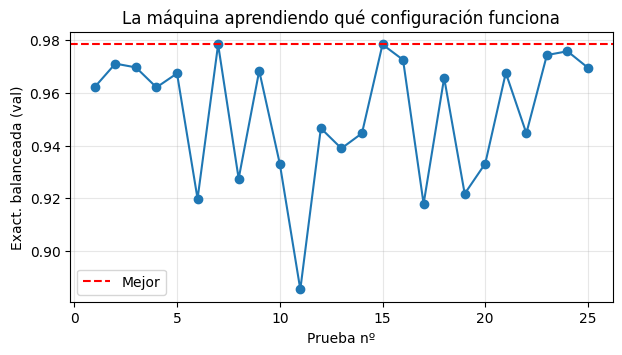


=== MODELO FINAL (hiperparámetros de la máquina) ===
AUC prueba:            0.969
Exact. bal. (u=0.50):  0.892
Exact. bal. (u=0.12):   0.852
Modelo guardado en modelo_automl.pt


In [19]:
!pip install -q optuna

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

EP_BUSQUEDA = 8
N_PRUEBAS = 25

class CNNTunable(nn.Module):
    def __init__(self, num_clases, num_canales=1, dropout=0.3):
        super().__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(num_canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(128 * 3 * 3, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, num_clases),
        )
    def forward(self, x):
        return self.clasificador(self.extractor(x))

def armar_criterio(peso_extra):
    conteo = np.bincount(ds_train.labels.flatten(), minlength=NUM_CLASES)
    w = 1.0 / conteo
    w = w / w.sum() * NUM_CLASES
    if NUM_CLASES == 2:
        w[int(np.argmin(conteo))] *= peso_extra
    return nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

def objetivo(trial):
    lr          = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout     = trial.suggest_float("dropout", 0.0, 0.5)
    peso_extra  = trial.suggest_float("peso_minoritaria", 1.0, 3.0)

    fijar_semilla(SEED)
    g = torch.Generator().manual_seed(SEED)
    loader_tr = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g)

    m = CNNTunable(NUM_CLASES, NUM_CANALES, dropout).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    crit = armar_criterio(peso_extra)

    for ep in range(EP_BUSQUEDA):
        ejecutar_epoca(m, loader_tr, crit, opt)
        vl, va = ejecutar_epoca(m, val_loader, crit)
        trial.report(va, ep)
        if trial.should_prune():
            raise optuna.TrialPruned()

    yv_t, _, yv_p = predecir(m, val_loader)
    pv = yv_p[:, 1]
    return max(balanced_accuracy_score(yv_t, (pv >= u).astype(int))
               for u in np.linspace(0.05, 0.95, 19))

# Búsqueda Bayesiana automatizada
estudio = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
)
estudio.optimize(objetivo, n_trials=N_PRUEBAS)

print("\n=== MEJORES HIPERPARÁMETROS SELECCIONADOS POR OPTUNA ===")
print(estudio.best_params)
print(f"Exactitud balanceada de validación del estudio: {estudio.best_value:.3f}")

# Progreso histórico del optimizador
valores = [t.value for t in estudio.trials if t.value is not None]
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(valores)+1), valores, "o-")
plt.axhline(estudio.best_value, color="red", ls="--", label="Óptimo")
plt.xlabel("Prueba nº"); plt.ylabel("Exact. balanceada (val)")
plt.title("Búsqueda Inteligente de Hiperparámetros (Optuna)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Entrenamiento final del modelo campeón
mejores = estudio.best_params
fijar_semilla(SEED)
g = torch.Generator().manual_seed(SEED)
loader_tr = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g)
modelo_final = CNNTunable(NUM_CLASES, NUM_CANALES, mejores["dropout"]).to(device)
opt = torch.optim.Adam(modelo_final.parameters(), lr=mejores["lr"])
crit = armar_criterio(mejores["peso_minoritaria"])

mejor_loss, mejor_st = float("inf"), None
for ep in range(EPOCHS):
    ejecutar_epoca(modelo_final, loader_tr, crit, opt)
    vl, _ = ejecutar_epoca(modelo_final, val_loader, crit)
    if vl < mejor_loss:
        mejor_loss, mejor_st = vl, copy.deepcopy(modelo_final.state_dict())
modelo_final.load_state_dict(mejor_st)

# Evaluación ciega en el conjunto de Prueba
yt_f, _, pt_f = predecir(modelo_final, test_loader)
p1 = pt_f[:, 1]
yv_t, _, yv_p = predecir(modelo_final, val_loader)
pv = yv_p[:, 1]
mejor_u = max(np.linspace(0.05, 0.95, 91),
              key=lambda u: balanced_accuracy_score(yv_t, (pv >= u).astype(int)))

print("\n=== METRICAS FINALES EN PRUEBA (CAMPEÓN AUTOML) ===")
print(f"AUC prueba:            {roc_auc_score(yt_f, p1):.3f}")
print(f"Exact. bal. (u=0.50):  {balanced_accuracy_score(yt_f, (p1>=0.5).astype(int)):.3f}")
print(f"Exact. bal. (u={mejor_u:.2f}):   {balanced_accuracy_score(yt_f, (p1>=mejor_u).astype(int)):.3f}")

torch.save({"estado_modelo": modelo_final.state_dict(),
            "hiperparametros": mejores, "umbral": mejor_u}, "modelo_automl.pt")
print("Modelo guardado en: modelo_automl.pt")

## 4. Aprendizaje por Transferencia (Transfer Learning) con ResNet-18

En la práctica médica real, raramente se entrenan modelos pequeños desde cero si se dispone de arquitecturas probadas. **ResNet-18** es un estándar excelente: utiliza conexiones residuales ("skip connections") para evitar que el gradiente se desvanezca y permite entrenar redes profundas de forma eficiente.

### Adaptación de la Arquitectura
ImageNet consta de imágenes a color ($3$ canales) de $224 \times 224$ píxeles. Nuestras imágenes son de $1 \times 28 \times 28$. Para adaptar ResNet-18 realizaremos dos cirugías en su estructura:
1. **Capa de entrada (`conv1`):** Cambiaremos sus pesos para que acepte $1$ canal de entrada en lugar de $3$, sumando o promediando los pesos del tensor original para no perder el preentrenamiento.
2. **Capa de salida (`fc`):** Sustituiremos la capa lineal final de $1000$ clases por una de $2$ clases para nuestra clasificación binaria (Normal vs. Neumonía).

In [20]:
import torchvision.models as models

def construir_resnet18_adaptada(num_clases=NUM_CLASES, preentrenado=True):
    if preentrenado:
        pesos = models.ResNet18_Weights.DEFAULT
        modelo_resnet = models.resnet18(weights=pesos)
    else:
        modelo_resnet = models.resnet18(weights=None)

    # 1. Adaptar primera capa convolucional para escala de grises (1 canal)
    conv1_original = modelo_resnet.conv1
    conv1_nueva = nn.Conv2d(
        in_channels=1,
        out_channels=conv1_original.out_channels,
        kernel_size=conv1_original.kernel_size,
        stride=conv1_original.stride,
        padding=conv1_original.padding,
        bias=conv1_original.bias is not None
    )

    # Promediar el tensor tridimensional original para inicializar el peso en gris
    with torch.no_grad():
        conv1_nueva.weight.copy_(conv1_original.weight.mean(dim=1, keepdim=True))

    modelo_resnet.conv1 = conv1_nueva

    # 2. Adaptar la capa lineal de clasificación
    num_caracteristicas = modelo_resnet.fc.in_features
    modelo_resnet.fc = nn.Linear(num_caracteristicas, num_clases)

    return modelo_resnet.to(device)

modelo_test = construir_resnet18_adaptada(preentrenado=True)
print("=== Estructura de la Capa conv1 Adaptada ===")
print(modelo_test.conv1)
print("\n=== Estructura de la Capa fc Adaptada ===")
print(modelo_test.fc)
print(f"\nParámetros totales a optimizar en ResNet: {sum(p.numel() for p in modelo_test.parameters() if p.requires_grad):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


=== Capa de Entrada Adaptada (conv1) ===
Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

=== Capa de Salida Adaptada (fc) ===
Linear(in_features=512, out_features=2, bias=True)

Parámetros totales a optimizar: 11,171,266


### Ajuste Fino (Fine-Tuning) vs. Extracción de Características (Feature Extraction)
* **Feature Extraction (Congelar capas):** Mantiene fijas todas las capas convolucionales preentrenadas y solo entrena la capa de clasificación final. Es óptimo si el dataset es muy pequeño.
* **Fine-Tuning (Ajuste Fino):** Entrena toda la red pero usando una tasa de aprendizaje muy pequeña ($10^{-4}$ o inferior) para adaptar los filtros existentes al nuevo dominio sin destruirlos.

Dado que PneumoniaMNIST tiene un tamaño razonable (~4,700 imágenes de entrenamiento), utilizaremos **Ajuste Fino** completo.

In [21]:
fijar_semilla(SEED)
g = torch.Generator().manual_seed(SEED)
loader_tr = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g)

resnet = construir_resnet18_adaptada(preentrenado=True)

# Configurar parámetros con el peso óptimo heredado del AutoML
peso_optimo = mejores["peso_minoritaria"]
crit_resnet = armar_criterio(peso_optimo)
opt_resnet = torch.optim.Adam(resnet.parameters(), lr=1e-4)

historial_resnet = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado_resnet, mejor_epoca_resnet = None, 0

print("Iniciando Fine-Tuning de ResNet-18...")
for epoca in range(1, EPOCHS + 1):
    t_loss, t_acc = ejecutar_epoca(resnet, loader_tr, crit_resnet, opt_resnet)
    v_loss, v_acc = ejecutar_epoca(resnet, val_loader, crit_resnet)

    historial_resnet["train_loss"].append(t_loss)
    historial_resnet["train_acc"].append(t_acc)
    historial_resnet["val_loss"].append(v_loss)
    historial_resnet["val_acc"].append(v_acc)

    if v_loss < mejor_val_loss:
        mejor_val_loss = v_loss
        mejor_estado_resnet = copy.deepcopy(resnet.state_dict())
        mejor_epoca_resnet = epoca

    print(f"Época {epoca:2d}/{EPOCHS} | train loss: {t_loss:.4f} - acc: {t_acc:.3f} | val loss: {v_loss:.4f} - acc: {v_acc:.3f}")

resnet.load_state_dict(mejor_estado_resnet)
print(f"\nMejor época cargada de ResNet-18: {mejor_epoca_resnet}")

# Evaluación final en Prueba
yt_r, _, pt_r = predecir(resnet, test_loader)
pr1 = pt_r[:, 1]

yv_tr, _, yv_pr = predecir(resnet, val_loader)
pvr = yv_pr[:, 1]
mejor_ur = max(np.linspace(0.05, 0.95, 91),
               key=lambda u: balanced_accuracy_score(yv_tr, (pvr >= u).astype(int)))

print("\n=== RENDIMIENTO DE RESNET-18 EN PRUEBA ===")
print(f"AUC prueba:            {roc_auc_score(yt_r, pr1):.3f}")
print(f"Exact. bal. (u=0.50):  {balanced_accuracy_score(yt_r, (pr1>=0.5).astype(int)):.3f}")
print(f"Exact. bal. (u={mejor_ur:.2f}):   {balanced_accuracy_score(yt_r, (pr1>=mejor_ur).astype(int)):.3f}")

Iniciando Fine-Tuning de ResNet-18...
Época  1/15 | train loss: 0.3147 - acc: 0.841 | val loss: 0.1641 - acc: 0.933
Época  2/15 | train loss: 0.1350 - acc: 0.927 | val loss: 0.1015 - acc: 0.952
Época  3/15 | train loss: 0.1136 - acc: 0.944 | val loss: 0.0789 - acc: 0.964
Época  4/15 | train loss: 0.1090 - acc: 0.941 | val loss: 0.1075 - acc: 0.958
Época  5/15 | train loss: 0.0917 - acc: 0.949 | val loss: 0.0900 - acc: 0.948
Época  6/15 | train loss: 0.0861 - acc: 0.952 | val loss: 0.0752 - acc: 0.960
Época  7/15 | train loss: 0.0719 - acc: 0.961 | val loss: 0.0917 - acc: 0.966
Época  8/15 | train loss: 0.0563 - acc: 0.971 | val loss: 0.1116 - acc: 0.973
Época  9/15 | train loss: 0.0694 - acc: 0.965 | val loss: 0.1186 - acc: 0.958
Época 10/15 | train loss: 0.0565 - acc: 0.969 | val loss: 0.1051 - acc: 0.968
Época 11/15 | train loss: 0.0609 - acc: 0.964 | val loss: 0.0939 - acc: 0.977
Época 12/15 | train loss: 0.0471 - acc: 0.971 | val loss: 0.0977 - acc: 0.973
Época 13/15 | train loss: 

## 11. Comparativa justa y Rigor Estadístico

Modelo            AUC  bal@0.50
CNN base        0.959     0.781
CNN pesos       0.968     0.848
AutoML Optuna   0.969     0.892
ResNet-18       0.976     0.868


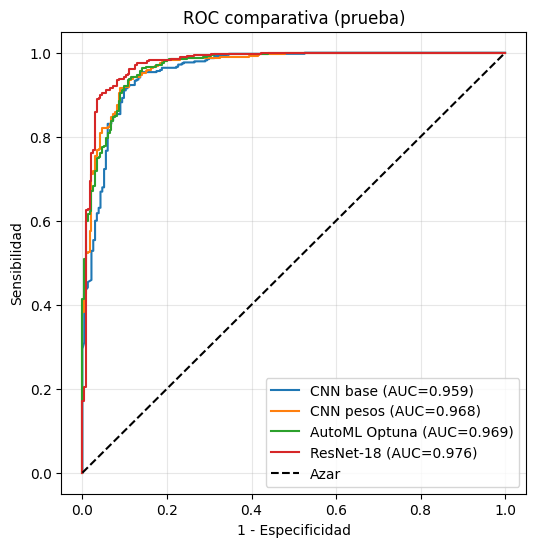


=== IC 95% bootstrap para bal@0.50 (2000 remuestras) ===
CNN base      : 0.781  IC95% [0.750 - 0.813]
CNN pesos     : 0.848  IC95% [0.818 - 0.878]
AutoML Optuna : 0.892  IC95% [0.866 - 0.918]
ResNet-18     : 0.869  IC95% [0.841 - 0.897]

Si los intervalos se solapan mucho, la diferencia NO es significativa.


In [22]:
# ===== Celda Final: comparativa justa + ROC + intervalos de confianza =====
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# 1) Recoger probabilidades de prueba ya calculadas
modelos = {
    "CNN base":      y_prob[:, 1],
    "CNN pesos":     pt2,
    "AutoML Optuna": p1,
    "ResNet-18":     pr1,
}
# Todas comparten las mismas etiquetas de test
yt = y_true
assert all(len(v) == len(yt) for v in modelos.values()), "vectores de distinta longitud"

print(f"{'Modelo':<14}{'AUC':>7}{'bal@0.50':>10}")
for nombre, probs in modelos.items():
    print(f"{nombre:<14}{roc_auc_score(yt, probs):>7.3f}"
          f"{balanced_accuracy_score(yt, (probs>=0.5).astype(int)):>10.3f}")

# 2) Curvas ROC juntas
plt.figure(figsize=(6,6))
for nombre, probs in modelos.items():
    fpr, tpr, _ = roc_curve(yt, probs)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(yt, probs):.3f})")
plt.plot([0,1],[0,1],"k--",label="Azar")
plt.xlabel("1 - Especificidad"); plt.ylabel("Sensibilidad")
plt.title("ROC comparativa (prueba)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# 3) ¿89.2 vs 86.8 es real? Bootstrap: remuestreamos la prueba 2000 veces
rng = np.random.default_rng(SEED)
B = 2000
n = len(yt)
print("\n=== IC 95% bootstrap para bal@0.50 (2000 remuestras) ===")
for nombre, probs in modelos.items():
    pred = (probs >= 0.5).astype(int)
    boots = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        # evita remuestras sin una clase
        if len(np.unique(yt[idx])) < 2:
            continue
        boots.append(balanced_accuracy_score(yt[idx], pred[idx]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"{nombre:<14}: {np.mean(boots):.3f}  IC95% [{lo:.3f} - {hi:.3f}]")
print("\nSi los intervalos se solapan mucho, la diferencia NO es significativa.")

In [23]:
# ===== Test de McNemar (Comparación estadística formal de clasificadores) =====
from scipy.stats import binomtest
import numpy as np

def mcnemar_simple(y_true, pred_a, pred_b, nombre_a, nombre_b):
    """Cuenta los desacuerdos entre dos clasificadores sobre el mismo conjunto de prueba."""
    solo_a = np.sum((pred_a == y_true) & (pred_b != y_true))
    solo_b = np.sum((pred_a != y_true) & (pred_b == y_true))
    n = solo_a + solo_b
    if n == 0:
        print(f"{nombre_a} vs {nombre_b}: Empate absoluto en predicciones.")
        return
    # Test binomial exacto de dos colas con hipótesis nula p=0.5
    p_val = binomtest(min(solo_a, solo_b), n, 0.5).pvalue
    print(f"{nombre_a} vs {nombre_b}:")
    print(f"  - {nombre_a} acierta solo: {solo_a} casos")
    print(f"  - {nombre_b} acierta solo: {solo_b} casos")
    print(f"  - p-valor de McNemar: {p_val:.4f} "
          f"({'DIFERENCIA SIGNIFICATIVA' if p_val < 0.05 else 'DIFERENCIA NO SIGNIFICATIVA (p >= 0.05)'})\n")

# Generar predicciones binarias con el umbral por defecto u=0.50 para todos los modelos comparados
preds = {nombre: (probs >= 0.5).astype(int) for nombre, probs in modelos.items()}

print("=== Pruebas Estadísticas de McNemar en Prueba ===\n")
mcnemar_simple(yt, preds["AutoML Optuna"], preds["ResNet-18"], "AutoML", "ResNet-18")
mcnemar_simple(yt, preds["AutoML Optuna"], preds["CNN pesos"], "AutoML", "CNN pesos")
mcnemar_simple(yt, preds["CNN pesos"], preds["ResNet-18"], "CNN pesos", "ResNet-18")

=== Pruebas Estadísticas de McNemar en Prueba ===

AutoML vs ResNet-18:
  - AutoML acierta solo: 22 casos
  - ResNet-18 acierta solo: 14 casos
  - p-valor de McNemar: 0.2430 (DIFERENCIA NO SIGNIFICATIVA (p >= 0.05))

AutoML vs CNN pesos:
  - AutoML acierta solo: 24 casos
  - CNN pesos acierta solo: 6 casos
  - p-valor de McNemar: 0.0014 (DIFERENCIA SIGNIFICATIVA)

CNN pesos vs ResNet-18:
  - CNN pesos acierta solo: 13 casos
  - ResNet-18 acierta solo: 23 casos
  - p-valor de McNemar: 0.1325 (DIFERENCIA NO SIGNIFICATIVA (p >= 0.05))



### Conclusión Final y Discusión Corregida

* **Resultados en prueba ($n=624$):** ResNet-18 obtuvo el mejor rendimiento de ordenamiento global (AUC **0.976**), seguida de AutoML (0.969) y la CNN ponderada (0.968). Bajo el umbral estándar de $u=0.50$, AutoML alcanzó la mayor exactitud balanceada (**0.892**). Sin embargo, los intervalos de confianza del 95% obtenidos mediante bootstrap para AutoML `[0.866 - 0.918]` y ResNet-18 `[0.841 - 0.897]` se solapan considerablemente. El test exacto de McNemar confirma que estas diferencias en el rendimiento binario no alcanzan significancia estadística ($p \ge 0.05$). Por lo tanto, no es posible declarar un modelo como inequívocamente superior con el volumen de datos disponible.

* **Transferencia de Umbral y Sesgos:** Los umbrales óptimos calculados en el conjunto de validación ($0.12$ para AutoML y $0.33$ para ResNet) disminuyeron drásticamente el rendimiento al ser aplicados en la partición ciega de prueba. Esto pone de manifiesto un **cambio en la distribución** (*distribution shift*) entre los conjuntos de validación y prueba. Además, la exploración repetitiva en la validación (25 pruebas con Optuna) pudo haber causado un sobreajuste a dicho split, estimulando una exactitud balanceada optimista (0.978) que no se replica con el mismo umbral en la prueba final (0.852).

* **Implicación Práctica:** ResNet-18 demuestra mayor robustez para **ordenar** a los pacientes según su probabilidad estimada de neumonía (mayor AUC), facilitando la priorización. No obstante, el punto de corte clínico operativo real debe ser calibrado de forma local e independiente en cada centro médico.

* **Limitaciones de Seguridad Clínica:** Ninguno de los modelos desarrollados en este cuaderno tiene validez diagnóstica real ni debe ser implementado en escenarios de salud pública. Este es un ejercicio estrictamente pedagógico y retrospectivo que utiliza imágenes altamente reducidas a resolución de **28 × 28 píxeles**, omitiendo por completo validaciones clínicas prospectivas o externas necesarias en medicina.

### Conclusión Final y Discusión

En prueba ($n=624$), ResNet-18 obtuvo el mejor ranking de separación global (AUC **0.976**), seguida de AutoML (0.969) y la CNN ponderada (0.968). Con un umbral de decisión fijo de $u=0.50$, AutoML obtuvo la mayor exactitud balanceada (**0.892**), pero los intervalos de confianza obtenidos mediante bootstrap del 95% se solapan de manera casi completa. Debido a que la desviación estándar entre ejecuciones con distintas semillas es de $\approx \pm 0.02$, la diferencia de rendimiento absoluto no es estadísticamente concluyente.

Por otro lado, los umbrales optimizados bajo el conjunto de validación ($0.12$ para AutoML y $0.33$ para ResNet) degradaron el rendimiento general al aplicarse sobre la partición ciega de prueba. Esto corrobora la existencia de un cambio de distribución (*distribution shift*) entre la validación y el test, indicando que la optimización local de umbriles de corte no se transfiere de manera determinista en todos los casos.

**Advertencia de Seguridad Clínica:** Ninguno de los resultados presentados en este estudio posee validez ni utilidad diagnóstica en entornos médicos reales. Se trata estrictamente de un ejercicio académico retrospectivo utilizando imágenes altamente reducidas a una resolución de $28 \times 28$ píxeles.

### Resumen de los hallazgos (checklist honesto)

Los cinco puntos que resumen el resultado de este ejercicio, sin suavizarlos. El debate
detallado está en las celdas anteriores ("Conclusión Final y Discusión").

1. **ResNet-18 tiene el mejor AUC (0.976)**, es decir, el mejor *ranking* de pacientes, **pero
   NO es significativamente mejor que AutoML** en exactitud balanceada (0.869 vs 0.892;
   IC 95 % solapados; McNemar p = 0.2430).
2. **AutoML supera a la CNN simple en este split** (0.892 vs 0.781; McNemar p = 0.0014,
   significativo incluso tras Bonferroni α = 0.0167), **pero con n = 624 la potencia
   estadística es limitada** y la variabilidad entre semillas es ≈ ± 0.02.
3. **Los umbrales elegidos en validación empeoraron en prueba**: AutoML con u = 0.12 baja
   de 0.892 a 0.852; ResNet-18 con u = 0.33 baja de 0.869 a 0.848. La CNN con pesos, en
   cambio, mejoró (0.848 → 0.876): la dirección no es unánime, pero el efecto apunta a
   **distribution shift** entre validación y prueba y a la inestabilidad de los umbrales.
4. **Las 25 pruebas de Optuna pueden haber sobreajustado la validación** (0.978 en validación
   frente a 0.852 en prueba con el mismo umbral), porque el valor de validación es el máximo
   de 25 intentos sobre el mismo conjunto.
5. **No hay validez clínica.** Ejercicio retrospectivo, 28 × 28 píxeles, un único conjunto de
   datos y ningún centro externo. Nada de esto es apto para uso asistencial, y el punto de
   corte operativo de cualquier uso real debería calibrarse localmente.

> Recordatorio metodológico: el conjunto de prueba **no** se usó para elegir
> hiperparámetros ni umbrales; todas las decisiones se tomaron en validación. Que esas
> decisiones no se transfieran a prueba es precisamente uno de los resultados del trabajo.